In [103]:
# Building WaveNet: https://arxiv.org/pdf/1609.03499

# problem with previous model: curshing too much info way to fast (char -> context seq. -> embedding)
# WaveNet : A deeper network, with a tree like fusion of context ( 2 char -> 2 bigrams -> 2 foregrams ...)

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [104]:
words = open("names.txt", 'r').read().splitlines()

In [105]:
chars = sorted(list(set(''.join(words))))
stoi = {s: i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i : s for s, i in stoi.items()}
print(itos)

vocab_size = len(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [106]:
# shuffle the words
import random
random.seed(42)
random.shuffle(words)

In [211]:
# building the dataset
block_size = 8 # context length

def build_dataset(words):
    
    X, Y = [], []
    for w in words:
    
        # print(w
        context = [0] * block_size
        for ch in w +'.' :
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context[1:] + [ix] # crop and append
    
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182484, 8]) torch.Size([182484])
torch.Size([22869, 8]) torch.Size([22869])
torch.Size([22793, 8]) torch.Size([22793])


In [212]:
# BASED ON TORCH.NN LIB

class Linear:

    def __init__ (self, fan_in, fan_out, bias=True):
        self.weight = torch.randn((fan_in, fan_out)) / fan_in**0.5
        self.bias = torch.zeros(fan_out) if bias else None

    def __call__(self, x):
        self.out = x @ self.weight
        if self. bias is not None:
            self.out += self. bias
        return self.out

    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])

# diff from pytorch we ues (N, C) or (N, L, C) as input so C will be the last dim
# where as pytorch accepts (N, C) or (N, C, L) we mean and var happens on (0, 2)
class BatchNorm1d:

    def __init__ (self, dim, eps= 1e-5, momentum=0.1):
        self.eps = eps
        self.momentum = momentum
        self.training = True
        # parameters (training with backprop)
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)
        # buffers (trained with running 'momentum update') i.e. Affine == True
        self.running_mean = torch.zeros(dim)
        self.running_var = torch.ones(dim)

    def __call__ (self, x):
        # calculate the forward pass
        if x.ndim == 2:
            dim = 0
        elif x.ndim == 3:
            dim = (0, 1)
        if self.training:
            xmean = x.mean(dim, keepdim=True)   # batch mean
            xvar = x.var(dim, keepdim=True, unbiased=True)     # btach std
        else:
            xmean = self.running_mean
            xvar = self.running_var
        xhat = (x - xmean) / torch.sqrt(xvar + self.eps) # normalize to unit vector
        self.out = self.gamma * xhat + self.beta
        # update the buffers
        if self.training:
            with torch.no_grad():
                self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
                self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar
        return self.out
    
    def parameters(self):
        return [self.gamma, self.beta]

class Tanh:
    def __call__ (self, x):
        self.out = torch.tanh(x)
        return self.out

    def parameters(self):
        return []

class Embedding:

    def __init__( self, num_embeddings, embedding_dim):
        self.weight = torch.randn((num_embeddings, embedding_dim))

    def __call__(self, ix):
        self.out = self.weight[ix]
        return self.out

    def parameters(self):
        return [self.weight]

class FlattenConsecutive: # diff than pytorch implementation

    def __init__(self, n): # consecutive element we would like to concatenate in the last dim
        self.n = n

    def __call__( self, x):
        B, T, C = x.shape
        x = x.view(B, T//self.n, C*self.n)
        if x.shape[1] == 1:
            x = x.squeeze(1)  # dim=1 will get squeezed as dim=1.shape = 1
        self.out = x
        return self.out

    def parameters(self):
        return []

class Sequential:

    def __init__(self, layers):
        self.layers = layers

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        self.out = x
        return self.out

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

In [213]:
torch.manual_seed(42);

In [214]:
n_embd = 24 # dim of character embedding paper
n_hidden = 128 # number of neurons in hidden layer

# C = torch.randn((vocab_size, n_embd))
#with batch norm

# original MLP
# model = Sequential([
#     Embedding(vocab_size, n_embd), 
#     FlattenConsecutive(block_size),  # same as before as 8*10 = 80
#     Linear(n_embd * block_size, n_hidden, bias=False), BatchNorm1d(n_hidden),  Tanh(),
#     Linear(           n_hidden, vocab_size),
# ])
# Embedding : (4, 8, 10)
# FlattenConsecutive : (4, 80)
# Linear : (4, 200)
# BatchNorm1d : (4, 200)
# Tanh : (4, 200)
# Linear : (4, 27)

# Wave net implementation
model = Sequential([
    Embedding(vocab_size, n_embd), # (4, 8, 10)
    FlattenConsecutive(2), Linear(n_embd * 2, n_hidden, bias=False), BatchNorm1d(n_hidden),  Tanh(), # Flatten: (4, 4, 20) -> Linear: (4, 4, 200)
    FlattenConsecutive(2), Linear(n_hidden * 2, n_hidden, bias=False), BatchNorm1d(n_hidden),  Tanh(), # Flatten:  (4, 2, 400) -> Linear:  (4, 2, 200)
    FlattenConsecutive(2), Linear(n_hidden * 2, n_hidden, bias=False), BatchNorm1d(n_hidden),  Tanh(), # Flatten: (4, 400) -> -> Linear:  (4, 200)
    Linear(           n_hidden, vocab_size),
])
# n_hidden = 200
# Embedding : (4, 8, 10)
# FlattenConsecutive : (4, 4, 20)
# Linear : (4, 4, 200)
# BatchNorm1d : (4, 4, 200)
# Tanh : (4, 4, 200)
# FlattenConsecutive : (4, 2, 400)
# Linear : (4, 2, 200)
# BatchNorm1d : (4, 2, 200)
# Tanh : (4, 2, 200)
# FlattenConsecutive : (4, 400)
# Linear : (4, 200)
# BatchNorm1d : (4, 200)
# Tanh : (4, 200)
# Linear : (4, 27)
    
with torch.no_grad():
    layers[-1].weight *= 0.1  # makes the last layer less confident
    
parameters = model.parameters() #[p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
    p.requires_grad = True

76579


In [215]:
# same optimization as the last time
max_step = 200000
batch_size = 32
lossi = []

for i in range(max_step):
    
    # minibatch construction
    ix = torch.randint(0, Xtr.shape[0], (batch_size,))
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X, Y

    # forward pass

    # outside of layer (needs calling)
    # emb = C[Xb] # embed the characters into vectors
    # x = emb.view(emb.shape[0], -1) # concatenate the vectors

    logits = model(Xb)
    loss = F.cross_entropy(logits, Yb) # loss function

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01 # step lr decay
    for p in parameters:
        p.data += - lr * p.grad

    # track stats
    if i % 10000 == 0:
        print(f'{i:7d}/{max_step:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())
    
    # if i >= 999:
    #     break # AFTER_DEBUG: would take out obviously to run full optimization

      0/ 200000: 3.6856
  10000/ 200000: 2.1617
  20000/ 200000: 2.7379
  30000/ 200000: 1.8948
  40000/ 200000: 1.6673
  50000/ 200000: 1.9549
  60000/ 200000: 2.3225
  70000/ 200000: 1.8687
  80000/ 200000: 1.6005
  90000/ 200000: 1.7810
 100000/ 200000: 1.9170
 110000/ 200000: 1.8611
 120000/ 200000: 2.1679
 130000/ 200000: 1.9619
 140000/ 200000: 1.6424
 150000/ 200000: 2.1834
 160000/ 200000: 2.3584
 170000/ 200000: 1.7738
 180000/ 200000: 1.8315
 190000/ 200000: 1.7780


In [203]:
for layer in model.layers:
    print(layer.__class__.__name__, ':', tuple(layer.out.shape))

Embedding : (32, 8, 10)
FlattenConsecutive : (32, 4, 20)
Linear : (32, 4, 68)
BatchNorm1d : (32, 4, 68)
Tanh : (32, 4, 68)
FlattenConsecutive : (32, 2, 136)
Linear : (32, 2, 68)
BatchNorm1d : (32, 2, 68)
Tanh : (32, 2, 68)
FlattenConsecutive : (32, 136)
Linear : (32, 68)
BatchNorm1d : (32, 68)
Tanh : (32, 68)
Linear : (32, 27)


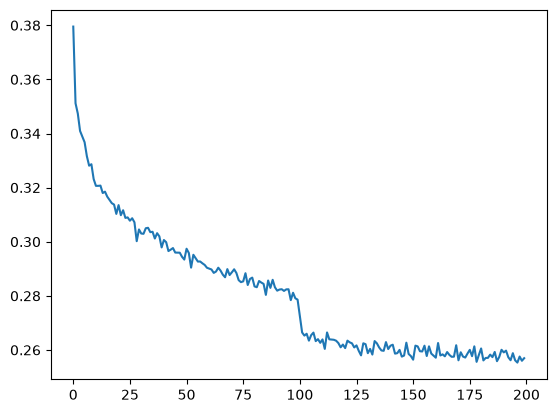

In [216]:
plt.plot(torch.tensor(lossi).view(-1, 1000).mean(1))

In [217]:
# put layers into eval mode (needed for batchnorm)
for layer in model.layers:
    layer.training = False

In [218]:
@torch.no_grad() # disables gradient tracking

def split_loss(split):
    x, y = {
        'train': (Xtr, Ytr),
        'val': (Xdev, Ydev),
        'test': (Xte, Yte)
    }[split]  # split will be used to index
    logits = model(x)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

split_loss('train')
split_loss('val')

# original model (context_size = 3):
# train 2.4252684116363525
# val 2.4194610118865967

# original model (context_size = 8, 22k param):
# train 1.9185
# val 2.0274

# Wavenet (22k param, n_hidden=68) - might have a bug in batchnorm1d
# train 1.950390338897705
# val 2.0277175903320312

# Wavenet (22k param, n_hidden=68) - bug fix
# train 1.9228018522262573
# val 2.012223243713379

# Wavenet (76k param, n_hidden=128, n_embd=24) 
# train 1.789450764656067
# val 1.978401780128479

train 1.789450764656067
val 1.978401780128479


In [219]:
# sampling 

for _ in range(20):

    out = []
    context = [0] * block_size  # all .'s
    while True:
        logits = model(torch.tensor([context]))
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break

    print(''.join(itos[i] for i in out))

apolj.
chotan.
heavontodio.
presley.
aiden.
aiwayrs.
clarin.
brenny.
dastyn.
sarah.
astaniya.
alayve.
aniah.
jaxston.
dillyn.
mitchaw.
emryn.
clarite.
jael.
aubreana.


In [196]:
ix = torch.randint(0, Xtr.shape[0], (4,)) # batch size of 4
Xb, Yb = Xtr[ix], Ytr[ix]
logits = model(Xb)
print(Xb.shape)
Xb

torch.Size([4, 8])


tensor([[ 0,  0,  0,  0,  0,  0,  6, 18],
        [ 0,  0,  0,  0,  0,  0, 20,  1],
        [ 0,  0,  0,  0,  0,  0,  0,  3],
        [ 0,  6, 18,  1, 14,  3, 15,  9]])

In [119]:
model.layers[0].out.shape # embedding layer's output

torch.Size([4, 8, 10])

In [122]:
model.layers[1].out.shape # flatten layer's output

torch.Size([4, 80])

In [123]:
model.layers[2].out.shape # linear layer's output

torch.Size([4, 200])

In [129]:
# Linear Layer overview
print((torch.randn(4, 80) @ torch.randn(80, 200) + torch.randn(200)).shape),

# pytorch MatMult also allows something like
(torch.randn(4, 5, 80) @ torch.randn(80, 200) + torch.randn(200)).shape # makes it easier for making wave net like structure

torch.Size([4, 200])


torch.Size([4, 5, 200])

In [131]:
# So what we want now
# instead of: 1, 2, 3, 4, 5, 6, 7 ,8 (context/block_size)
print((torch.randn(4, 80) @ torch.randn(80, 200) + torch.randn(200)).shape)

# we need: [1, 2], [3, 4], [5, 6], [7 ,8] (context/block_size)
print((torch.randn(4, 4, 20) @ torch.randn(20, 200) + torch.randn(200)).shape)

# and then:  [1, 2, 3, 4], [5, 6, 7 ,8] (context/block_size)
print((torch.randn(4, 2, 40) @ torch.randn(40, 200) + torch.randn(200)).shape)

torch.Size([4, 200])
torch.Size([4, 4, 200])
torch.Size([4, 2, 200])


In [152]:
e = torch.randn(4, 8, 10)# goal: want this to be (4, 4, 20) where consecutive 10-d vectors get concatenated
# e.view(4, -1).shape # Flatten layer ( not what we want)

explicit = torch.cat((e[:, ::2, :], e[:, 1::2, :]), dim=2) # one way  ( works because dim=2)
explicit.shape

# That’s what would happen with dim=1. The dim argument decides which axis gets longer.

# Call the two halves A = e[:, ::2, :] (positions 0,2,4,6) and B = e[:, 1::2, :] (positions 1,3,5,7). Both are (4, 4, 10).

# dim=1 (what you pictured): stack along the position axis.

# torch.cat((A, B), dim=1)  ->  shape (4, 8, 10)
# positions: 0, 2, 4, 6, 1, 3, 5, 7

# Still 8 positions with 10 numbers each, just reordered.

# dim=2 (what the code does): join along the embedding axis. Row i of A gets glued side by side with row i of B.

# torch.cat((A, B), dim=2)  ->  shape (4, 4, 20)

# row 0: [pos0 (10 nums) | pos1 (10 nums)]
# row 1: [pos2 (10 nums) | pos3 (10 nums)]
# row 2: [pos4 (10 nums) | pos5 (10 nums)]
# row 3: [pos6 (10 nums) | pos7 (10 nums)]

# Row 0 of A is pos0 and row 0 of B is pos1, so they end up together. Same for the other rows.

# The rule is that every dimension except the one you concatenate on must match, and those dimensions are paired up index by index. Only the dim axis grows.

torch.Size([4, 4, 20])

In [149]:
list(range(10))[::2]

[0, 2, 4, 6, 8]

In [151]:
(e.view(4, 4, 20) == explicit).all()  # another way

tensor(True)

In [179]:
# batchnorm bug::

e = torch.randn(32, 4, 68)
emean = e.mean(0, keepdim=True) # (1, 4, 68) : what we want = (1, 1, 68)
evar = e.var(0, keepdim=True) # (1, 4, 68) : what we want = (1, 1, 68)
ehat = (e - emean)/torch.sqrt(evar * 1e-5) # (32, 4, 68) broadcasted correctly fine

model.layers[3].running_mean.shape

# wanted = (1, 1, 68)

# Fix:
# From torch.mean (torch docx)

# the dim param can not only be int but also tuple of ints
# so we can pass something like (range(len(x.shape)-1)) to torch.mean and should work

e = torch.randn(32, 4, 68)
emean = e.mean((0, 1), keepdim=True) # (1, 1, 68) : what we want = (1, 1, 68) good
evar = e.var((0, 1), keepdim=True) # (1, 1, 68) : what we want = (1, 1, 68) good
ehat = (e - emean)/torch.sqrt(evar * 1e-5) # (32, 4, 68) broadcasted correctly fine